# Figure 5 — a smooth pulse at $L = 10000$

One long run from a one-period sinusoidal initial guess, to show the geodesic step
holds up when the pulse is orders of magnitude longer than the gate count.

**Units.** A coefficient is a phase per segment, $\phi = h\,\Delta t$ ($\hbar = 1$), so the
physics enters through $\Delta t = T/L$. Internally everything is measured against the
fixed ZZ coupling $g$, time in $1/g$ and fields in $g$, with the gate time held at
$gT = 5\pi/8$, two and a half times the $\pi/4$ a CNOT needs, so that a larger $L$ subdivides the same
pulse (a drift phase of $gT/L$ per segment) rather than lengthening it. The printed
numbers are quoted in the conventions of QuEra's Aquila, radians per microsecond and
micrometres; the figure shows $\Omega/2\pi$ and $\Delta/2\pi$ in MHz against time in
$\mu$s. Aquila's Hamiltonian is a global Rabi drive $\Omega/2$, a global detuning
$-\Delta\,n$, a local detuning $-\Delta_{\rm loc} h_i\,n$ on a static site pattern, and a
van der Waals shift $V = C_6/r^6$ on $n\,n$, with $n = (I - Z)/2$ the Rydberg projector.
Expanding $n\,n$ gives the ZZ coupling $g = V/4$ (the single-atom remainders fold into
$\Delta$), so the model's fields are $\Omega = 2h_X$, $\Delta = 2h_Z + V/2$ and
$\Delta_{\rm loc} = 2\delta$ on the control atom. A $1\,\mu$s program fixes $g = 1.96$
rad/$\mu$s, $V = 7.9$ rad/$\mu$s and an atom spacing of $9.4\,\mu$m from
$C_6 = 2\pi \times 862690$ rad $\mu$s$^{-1}\mu$m$^6$; Aquila's 15.8 rad/$\mu$s Rabi limit
and its 250 rad/$\mu$s$^2$ slew limit would allow 0.8 $\mu$s for this pulse, whose $\Omega$
peaks near 13 at 1 $\mu$s. The initial guess is deterministic: one period of a sine of
amplitude $1.5g$ in $\Omega$ and of a cosine in $\Delta$, which the optimiser moves by
somewhat more than its own size (smoothed-noise guesses converge too). Aquila requires the Rabi amplitude to
start and end at zero, so a fixed envelope inside the parameter transform ramps the two
global fields from zero over the first and last 50 ns, its shortest waveform step, with a
raised-cosine ramp so that the slope is continuous where the ramp ends, and the optimiser
solves for the pulse in between; $\Delta$ then rests at its $V/2$ baseline
at the ends. The local detuning is held static for the whole program, as in the model;
Aquila would ramp it too, a cost at the percent level that is left out here. The polish,
a 25 ns filter followed by a short re-optimisation, is applied twice; its width is below the
50 ns waveform spacing, so a hardware version would be designed on that grid. With coherence times of 6 to 11 $\mu$s a microsecond gate loses
of order ten percent to decoherence there: the figure is about the optimiser at
$L = 10000$, not an achievable fidelity.

**Controls.** Two global fields and one static offset: a Rabi drive $\Omega(t)$ and a
detuning $\Delta(t)$ shared by both atoms, plus a constant $Z$ offset $\delta = 16g$ on the
control atom, with the ZZ coupling as the drift. On their own the two global fields see
only the exchange-symmetric part of the problem and no CNOT is reachable; the offset
breaks that symmetry and makes the pair fully controllable, as a light shift on one atom
does in a Rydberg array under global beams. It also sets the pace: the atoms are only
told apart on a time scale $1/\delta$, and the shortest gate found is close to
$gT \approx \pi/4 + \pi/\delta$. With $\delta = 2g$ a gentle reshaping of the guess needs
$gT = 2\pi$; with $\delta = 16g$, a local detuning of $2\pi \times 10$ MHz and half of what
Aquila allows, the gate fits in $gT = 5\pi/8$ with the fields almost at rest where the ramps
end, at the price of a pulse the optimiser largely designs itself ($\pi/2$ is reachable too,
but its fields pile up against the ramps and break the slew limit). The local detuning is
not drawn in the figure; it is a constant. The tie
between the two $Z$ coefficients is affine, so it goes through the library's
`param_transform`: the free parameters per segment are $(\Omega, \Delta)$, mapped to the
four local coefficients with the offset added to the control atom's $Z$. That leaves
$P = 2L$ parameters driving the full 15-dimensional target space.


In [1]:
import warnings

from common import *

In [2]:
def gaussian_kernel(width, n_sigma=3):
    r"""A Gaussian smoothing kernel of **unit sum**, as a 1-D array
    Args:
        width: The Gaussian's standard deviation, in gate segments.
        n_sigma: Half-width of the truncated support, in units of ``width``.

    Returns:
        A ``(2 * radius + 1,)`` array summing to 1, with
        ``radius = ceil(n_sigma * width)``.
    """
    radius = max(1, int(np.ceil(n_sigma * width)))
    offsets = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (offsets / width) ** 2)
    return kernel / kernel.sum()

def smooth_along_time(fields, width, n_sigma=3, match_rms=True):
    r"""Smooth each control field along the gate axis, from zero back to zero

    Args:
        fields: ``(L, K_proj)`` array; column ``k`` is one control's time trace.
        width: Gaussian sigma in gate segments.
        n_sigma: Half-width of the kernel support, in units of ``width``. It
            sets the ramp length too, the two being the same number.
        match_rms: Rescale to the live-window RMS of ``fields``. Right for a
            white-noise draw, whose power the kernel removes; wrong for a pulse
            that is already smooth, which the kernel leaves at its amplitude.

    Returns:
        A ``(L, K_proj)`` array whose first and last rows are exactly zero.

    Raises:
        ValueError: If the two ramps leave no live window between them, i.e.
            ``2 * (radius + 1) >= L``.
    """
    if not width:
        return fields
    steps = fields.shape[0]
    kernel = gaussian_kernel(width, n_sigma)
    margin = (kernel.size - 1) // 2 + 1
    if 2 * margin >= steps:
        raise ValueError(
            f"sigma = {width:g} over {n_sigma} sigma needs {2 * margin} segments "
            f"of ramp, which is all of L = {steps}"
        )
    live = slice(margin, steps - margin)
    gated = np.zeros_like(fields)
    gated[live] = fields[live]
    smoothed = np.stack(
        [np.convolve(gated[:, k], kernel, "same") for k in range(fields.shape[1])],
        axis=1,
    )
    scale = np.sqrt(np.mean(smoothed[live] ** 2))
    if not match_rms or scale == 0:
        return smoothed
    return smoothed * (np.sqrt(np.mean(fields[live] ** 2)) / scale)



In [3]:
N_QUBITS_L = 2
TARGET_L = "CNOT"
L_LARGE = 10000

# Scales, in units of the fixed ZZ coupling g: time in 1/g, fields in g. The gate
# time is held at g T = 5 pi / 8, so a segment carries a drift phase g dt = g T / L and
# extra L subdivides the pulse rather than lengthening it: the coupling one
# segment sees falls as g / L, and the pulse stays a few 1/g long at any L.
G_T = 5 * np.pi / 8  # g T, the total gate time (2.5 times the pi/4 a CNOT needs)
GUESS_AMPLITUDE_G = 1.5  # amplitude of the sinusoidal initial guess, in units of g
G_DT = G_T / L_LARGE  # g dt, one segment

SPREAD_L = GUESS_AMPLITUDE_G * G_DT / np.pi  # the library's own random draw, unused here
DRIFT_L = np.array([G_DT])  # ZZ phase per segment, g T / L


def sinusoidal_guess():
    """``(L, 2)`` free parameters: one period of ``A sin`` for Omega, ``A cos`` for Delta.

    A deterministic guess in place of smoothed noise. The sine is zero at both
    ends by itself; the envelope in the transform takes the cosine there.
    """
    t = (np.arange(L_LARGE) + 0.5) / L_LARGE
    amplitude = GUESS_AMPLITUDE_G * G_DT
    return np.stack(
        [amplitude * np.sin(2 * np.pi * t), amplitude * np.cos(2 * np.pi * t)], axis=1
    )

# Physical scale, in QuEra Aquila's conventions (rad/us and um, hbar = 1). Its
# Hamiltonian is a global Rabi drive Omega/2 X, a global detuning -Delta n, a local
# detuning -Delta_loc h_i n on a static site pattern, and C6 / r^6 n n between
# Rydberg populations n = (I - Z) / 2. Expanding n n gives g = V / 4 with
# V = C6 / r^6, and puts the model's fields at Omega = 2 h_X, Delta = 2 h_Z + V / 2
# and Delta_loc = 2 delta on the control atom. The gate time is Aquila's longest
# program, which fixes g and with it V and the atom spacing.
T_US = 1.0  # us, the gate time; the Rabi and slew limits would allow 0.8 us for this pulse
G_RAD_US = G_T / T_US  # rad/us, the coupling that makes g T = 5 pi/8
V_RAD_US = 4 * G_RAD_US  # rad/us, the van der Waals shift of |rr>
C6_AQUILA = 2 * np.pi * 862690.0  # rad/us um^6
R_UM = (C6_AQUILA / V_RAD_US) ** (1 / 6)  # um, the atom spacing that gives V
OMEGA_MAX_AQUILA = 15.8  # rad/us, Aquila's largest Rabi frequency
DELTA_MAX_AQUILA = 125.0  # rad/us, its global detuning range
OMEGA_SLEW_AQUILA = 250.0  # rad/us^2, its Rabi slew-rate limit
DT_US = T_US / L_LARGE  # us, one segment
TO_RAD_US = G_RAD_US / G_DT  # phase per segment -> field in rad/us


# Two global fields and one static offset. Per segment the free parameters are
# (Omega, Delta): a Rabi drive and a detuning shared by both atoms. The control
# atom (atom 1, the left tensor factor) also carries a constant Z offset of
# OFFSET_G, which is what lets global fields tell the two atoms apart: without
# it no CNOT is reachable, and it sets the pace, the shortest gate found being
# close to g T = pi/4 + pi/delta. At 2 g a gentle reshaping of the guess needs
# g T = 2 pi; at 16 g the gate fits in g T = 5 pi/8 with quiet ramp ends (pi/2 works
# too, but its fields pile up against the ramps and break Aquila's slew limit).
# The tie between the two Z coefficients is affine, so it goes through the
# library's `param_transform` rather than a linear constraint.
N_FIELDS = 2
FIELD_NAMES = ["Omega", "Delta"]
OFFSET_G = 16.0  # static Z offset on the control atom, in units of g

# Aquila needs the Rabi amplitude to start and end at zero, so the two global
# fields are multiplied by a fixed envelope that ramps from zero over the first
# and last RAMP_NS as a raised cosine, whose slope vanishes at both ends so the
# pulse has no kink where the ramp meets it; the local detuning stays static. The envelope
# lives inside the transform, which the library calls with the segment index
# when it takes two arguments, so the optimiser only ever sees ramped pulses.
RAMP_NS = 50.0  # Aquila's shortest waveform step
RAMP_SEGMENTS = int(round(RAMP_NS * 1e-3 / DT_US))
_edge = np.minimum(np.arange(L_LARGE) + 1, L_LARGE - np.arange(L_LARGE))  # segments from the nearer end
ENVELOPE = np.where(
    _edge < RAMP_SEGMENTS, 0.5 * (1 - np.cos(np.pi * _edge / RAMP_SEGMENTS)), 1.0
)
ENVELOPE_J = jnp.asarray(ENVELOPE)


def global_transform(phi, step):
    """``(Omega, Delta)`` of segment ``step`` -> the ``[IX, IZ, XI, ZI]`` coefficients."""
    e = ENVELOPE_J[step]
    return jnp.array([e * phi[0], e * phi[1], e * phi[0], e * phi[1] + OFFSET_G * G_DT])


def aquila_fields(pulse):
    """``(Omega, Delta)`` in rad/us for an ``(L, 2)`` block of free parameters.

    The envelope is applied here as the transform applies it, so these are the
    fields the machine would play; ``Delta`` includes its ``V / 2`` baseline.
    """
    omega = 2 * ENVELOPE * pulse[:, 0] * TO_RAD_US
    return omega, 2 * ENVELOPE * pulse[:, 1] * TO_RAD_US + V_RAD_US / 2


LOCAL_DETUNING_US = 2 * OFFSET_G * G_RAD_US  # rad/us, the static Delta_loc


# Under the transform the free parameters are real while the Jacobian stays
# complex, so JAX warns once that it drops the imaginary part of a cotangent.
# That is exactly what a real parameter wants, so the warning is noise here.
warnings.filterwarnings("ignore", message="Casting complex values to real")


def large_parameters():
    """The two-atom model: all four local operators, driven through the transform."""
    return make_parameters_cnot(
        L_LARGE,
        TARGET_L,
        spread=SPREAD_L,
        drift_values=DRIFT_L,
        param_transform=global_transform,
        n_experimental_params=N_FIELDS,
    )


MAX_STEP_L = 1.0
LARGE_SEED = 0
LARGE_LINE_SEARCH = Armijo()


def large_config(n, target, steps, seed):
    """Everything that changes this block's numbers"""
    return {
        "tag": (
            f"large_{target}_L{steps}_gT{G_T / np.pi:g}pi"
            f"_sin1cos1_A{value_slug(GUESS_AMPLITUDE_G)}g"
            f"_globalXZ_offset{value_slug(OFFSET_G)}g_globalcosramp{RAMP_NS:g}ns"
        ),
        "kind": "large-L-smooth-global",
        "n_qubits": n,
        "target": target,
        "fields": FIELD_NAMES,
        "offset_g": OFFSET_G,
        "offset_atom": 1,
        "ramp_ns": RAMP_NS,
        "ramped": "global fields only",
        "ramp_shape": "raised cosine",
        "t_us": T_US,
        "steps": steps,
        "guess": "Omega A sin(2 pi t / T), Delta A cos(2 pi t / T), one period",
        "guess_amplitude_g": GUESS_AMPLITUDE_G,
        "seed": seed,
        "g_t": G_T,
        "g_dt": G_DT,
        "max_steps": MAX_STEPS,
        "precision": PRECISION,
        "line_search": repr(LARGE_LINE_SEARCH),
        "geope_max_step": MAX_STEP_L,
    }


def large_paths(cfg):
    """``(npz, json)`` for this block — one folder for the whole figure.

    Not one folder per anything: this is a *single* run, not a sweep, so the
    three-deep nesting Figure D1 and Extra Figure 4 need would be one directory per file.
    """
    return cache_paths(cfg, "large")


def large_run(force=False, verbose=True):
    """The one run, reading the cache. Returns ``(block, note)``.
    """
    cfg = large_config(N_QUBITS_L, TARGET_L, L_LARGE, LARGE_SEED)
    npz_path, json_path = large_paths(cfg)
    if npz_path.exists() and not force:
        with np.load(npz_path) as handle:
            return {k: handle[k] for k in handle.files}, "cached"

    params = large_parameters()
    init = sinusoidal_guess()

    optimiser = Geope(params, history=History())
    if verbose:
        print(f"  {cfg['tag']:44s} computing", flush=True)
    started = time.perf_counter()
    # No `warm_up`: one run pays one JIT trace either way, and charging it to
    # the run is what the per-step clock below is there to separate out.
    fidelity, seconds = timed_trajectory(
        optimiser,
        init,
        LARGE_LINE_SEARCH,
        label=TARGET_L if verbose else "",
        max_step_size=MAX_STEP_L,
    )
    block = {
        "fidelity": fidelity,
        "seconds": seconds,
        "init": init,
        "final": np.real(np.asarray(params.parameters)),
        "labels": np.array(FIELD_NAMES),
        "n_free": np.asarray(params.free().size),
    }
    npz_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(npz_path, **block)
    json_path.write_text(
        json.dumps(
            {**cfg, "steps_taken": int(fidelity.size - 1)}, indent=1, sort_keys=True
        )
    )
    return block, f"computed in {time.perf_counter() - started:.0f}s"


large, large_note = large_run()
fidelity = large["fidelity"]
init, final = large["init"], large["final"]
labels = [str(s) for s in large["labels"]]
n_free = int(large["n_free"])
seconds = large["seconds"]
n_taken = fidelity.size - 1  
per_step = np.diff(seconds)

print(
    f"target      : {TARGET_L} on {N_QUBITS_L} atoms, L = {L_LARGE}, global fields "
    f"{' '.join(labels)}, offset {OFFSET_G:g} g on the control atom  ({large_note})"
)
print(
    f"units       : g T = {G_T / np.pi:g} pi; on Aquila T = {T_US:g} us, so g = {G_RAD_US:.2f} rad/us, "
    f"V = 4 g = {V_RAD_US:.2f} rad/us at r = {R_UM:.2f} um;\n"
    f"              dt = {DT_US * 1e3:.1f} ns; guess: one period of a sine (Omega) and a cosine (Delta), "
    f"amplitude {GUESS_AMPLITUDE_G:g} g = {2 * GUESS_AMPLITUDE_G * G_RAD_US:.1f} rad/us in Omega"
)
print(f"parameters  : P = {n_free}")
print(f"steps       : {n_taken} of at most {MAX_STEPS}")
print(
    f"wall clock  : {float(seconds[-1]):.1f} s total, of which "
    f"{float(per_step[0]) * 1e3:.0f} ms is step 1 (the JIT trace);\n"
    f"              {float(np.median(per_step[1:])) * 1e3:.0f} ms/step thereafter"
)
print(f"infidelity  : {1 - fidelity[-1]:.3e}   (converged: {fidelity[-1] > PRECISION})")
print(f"roughness   : {roughness(init):.4f} guess -> {roughness(final):.4f} optimised")
# The headline number, and the reason panel (b) draws one pulse and not two:
# at this L the guess and the solution coincide at plotting resolution.
shift = np.sqrt(np.mean((final - init) ** 2)) / np.sqrt(np.mean(init**2))
print(
    f"displaced   : {100 * shift:.1f}% of the guess in RMS "
    f"(max |delta| = {np.abs(final - init).max():.1e})"
)
# Exactly zero in the guess, by construction; nothing holds them there during
# the run, so this is the honest check that the run does not walk them off.
omega_0, delta_0 = aquila_fields(init)
omega_1, delta_1 = aquila_fields(final)
print(
    f"ends        : Omega at segments 0 and L-1 is {np.abs(omega_1[[0, -1]]).max():.1e} rad/us, "
    f"and {np.abs(omega_1[[RAMP_SEGMENTS, -RAMP_SEGMENTS - 1]]).max():.2f} rad/us where the ramps end"
)
print(
    f"amplitude   : peak |Omega| = {np.abs(omega_0).max():.1f} rad/us guess -> {np.abs(omega_1).max():.1f} optimised "
    f"(Aquila max {OMEGA_MAX_AQUILA:g}); Delta in [{delta_1.min():.1f}, {delta_1.max():.1f}] rad/us "
    f"(|Delta| <= {DELTA_MAX_AQUILA:g});\n              Delta_loc = {LOCAL_DETUNING_US:.2f} rad/us on the control atom, static; "
    f"Omega and Delta ramped over {RAMP_NS:g} ns at each end; "
    f"max |dOmega/dt| = {np.abs(np.diff(omega_1)).max() / DT_US:.0f} rad/us^2 (limit {OMEGA_SLEW_AQUILA:g})"
)
print(
    f"\nFor scale, a Newton step here would form a {n_free} x {n_free} Hessian "
    f"({n_free**2 * 8 / 1e6:.0f} MB)\nand an eigendecomposition of it, every iteration."
)

target      : CNOT on 2 atoms, L = 10000, global fields Omega Delta, offset 16 g on the control atom  (cached)
units       : g T = 0.625 pi; on Aquila T = 1 us, so g = 1.96 rad/us, V = 4 g = 7.85 rad/us at r = 9.40 um;
              dt = 0.1 ns; guess: one period of a sine (Omega) and a cosine (Delta), amplitude 1.5 g = 5.9 rad/us in Omega
parameters  : P = 20000
steps       : 13 of at most 200
wall clock  : 4.9 s total, of which 857 ms is step 1 (the JIT trace);
              331 ms/step thereafter
infidelity  : 2.749e-12   (converged: True)
roughness   : 0.0006 guess -> 0.0013 optimised
displaced   : 128.3% of the guess in RMS (max |delta| = 6.2e-04)
ends        : Omega at segments 0 and L-1 is 1.7e-08 rad/us, and 3.94 rad/us where the ramps end
amplitude   : peak |Omega| = 5.9 rad/us guess -> 13.3 optimised (Aquila max 15.8); Delta in [-7.8, 11.0] rad/us (|Delta| <= 125);
              Delta_loc = 62.83 rad/us on the control atom, static; Omega and Delta ramped over 50 ns at each en

In [4]:
# Polish: Gaussian-filter the solution, then re-optimise briefly from there,
# and repeat. Each round removes most of the fine structure the previous
# re-optimisation put back, so two rounds leave a cleaner pulse than one at
# the same filter width.
POLISH_SIGMA_G = G_T / 40  # 1/g, filter width (bandwidth ~ 4 g)
POLISH_SIGMA = POLISH_SIGMA_G / G_DT  # in gate segments
POLISH_MAX_STEPS = 20  # per round
POLISH_ROUNDS = 2


def polish_run(final, force=False, verbose=True):
    """Filter ``final`` and re-optimise it, `POLISH_ROUNDS` times over.

    The filter is `smooth_along_time` without the RMS match -- the solution is
    already band-limited, so the kernel leaves its amplitude alone -- and under
    the same zero boundary, which pulls the ends the first run let drift back to
    exactly zero. That costs fidelity, and the short re-optimisation from the
    filtered pulse buys it back; it starts next to a solution, so it moves the
    pulse far less than the first run moved the guess. The next round starts
    from the re-optimised pulse.

    Returns ``(block, note)``, cached beside the run it polishes; the block
    holds one ``fidelity_<round>`` trajectory per round, the first round's
    ``filtered`` pulse and the final ``polished`` one.
    """
    cfg = {
        **large_config(N_QUBITS_L, TARGET_L, L_LARGE, LARGE_SEED),
        "kind": "large-L-polish-global",
        "polish_sigma": POLISH_SIGMA,
        "polish_max_steps": POLISH_MAX_STEPS,
        "polish_rounds": POLISH_ROUNDS,
    }
    cfg["tag"] += f"_polish{POLISH_SIGMA:g}x{POLISH_ROUNDS}"
    npz_path, json_path = large_paths(cfg)
    if npz_path.exists() and not force:
        with np.load(npz_path) as handle:
            return {k: handle[k] for k in handle.files}, "cached"

    params = large_parameters()
    optimiser = Geope(params, history=History())
    block, current, total_seconds = {}, final, 0.0
    for round_ in range(POLISH_ROUNDS):
        filtered = smooth_along_time(current, POLISH_SIGMA, match_rms=False)
        fidelity, seconds = timed_trajectory(
            optimiser,
            filtered,
            LARGE_LINE_SEARCH,
            label=f"{TARGET_L} polish {round_ + 1}" if verbose else "",
            max_step_size=MAX_STEP_L,
            max_steps=POLISH_MAX_STEPS,
        )
        current = np.real(np.asarray(params.parameters))
        block[f"fidelity_{round_}"] = fidelity
        block[f"seconds_{round_}"] = seconds
        if round_ == 0:
            block["filtered"] = filtered
        total_seconds += float(seconds[-1])
    block["polished"] = current
    npz_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(npz_path, **block)
    json_path.write_text(
        json.dumps(
            {
                **cfg,
                "steps_taken": [
                    int(block[f"fidelity_{r}"].size - 1) for r in range(POLISH_ROUNDS)
                ],
            },
            indent=1,
            sort_keys=True,
        )
    )
    return block, f"{total_seconds:.1f}s"


polish, polish_note = polish_run(final)
filtered, polished = polish["filtered"], polish["polished"]
rounds = [polish[f"fidelity_{r}"] for r in range(POLISH_ROUNDS)]
print(
    f"polish      : sigma = {POLISH_SIGMA_G / G_RAD_US * 1e3:.0f} ns, "
    f"{POLISH_ROUNDS} rounds ({polish_note})"
)
print(
    f"infidelity  : {1 - fidelity[-1]:.2e} solution -> "
    + " -> ".join(
        f"{1 - f[0]:.1e} filtered -> {1 - f[-1]:.1e} after {f.size - 1} steps"
        for f in rounds
    )
)
print(
    f"roughness   : {roughness(final):.4f} solution -> {roughness(filtered):.4f} "
    f"filtered -> {roughness(polished):.4f} polished"
)
move = np.sqrt(np.mean((polished - final) ** 2)) / np.sqrt(np.mean(final**2))
print(f"displaced   : {100 * move:.2f}% of the solution in RMS, over both rounds")
omega_p, delta_p = aquila_fields(polished)
print(
    f"ends        : |Omega| where the ramps end is {np.abs(omega_1[[RAMP_SEGMENTS, -RAMP_SEGMENTS - 1]]).max():.2f} rad/us solution -> "
    f"{np.abs(omega_p[[RAMP_SEGMENTS, -RAMP_SEGMENTS - 1]]).max():.3f} polished; peak |Omega| {np.abs(omega_p).max():.1f} rad/us polished"
)
print(
    f"slew        : max |dOmega/dt| = {np.abs(np.diff(omega_p)).max() / DT_US:.0f} rad/us^2 polished "
    f"(limit {OMEGA_SLEW_AQUILA:g}); the plotted pulse is the polished one"
)


polish      : sigma = 25 ns, 2 rounds (cached)
infidelity  : 2.75e-12 solution -> 4.3e-02 filtered -> 3.3e-10 after 6 steps -> 7.4e-03 filtered -> 9.1e-11 after 6 steps
roughness   : 0.0013 solution -> 0.0009 filtered -> 0.0009 polished
displaced   : 30.14% of the solution in RMS, over both rounds
ends        : |Omega| where the ramps end is 3.94 rad/us solution -> 0.295 polished; peak |Omega| 13.0 rad/us polished
slew        : max |dOmega/dt| = 141 rad/us^2 polished (limit 250); the plotted pulse is the polished one


figures/fig5_large_L_CNOT_L10000.pdf


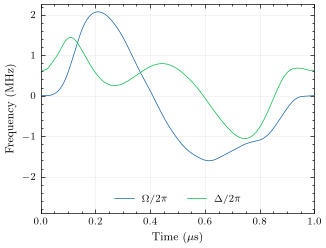

In [5]:
fig = plt.figure(figsize=(ONE_COLUMN, 3))
# Axes: time in us, fields as frequencies Omega / 2 pi and Delta / 2 pi in MHz
# (Aquila quotes rad/us; divide by 2 pi). Omega = 2 h_X is the Rabi
# frequency shared by both atoms (a negative value means a laser phase of pi),
# Delta = 2 h_Z + V / 2 the global detuning. The static local detuning on the
# control atom is a constant and is not drawn.
gs = fig.add_gridspec(1, 1)
ax_pulse = fig.add_subplot(gs[0, 0])

time_us = np.arange(L_LARGE) * DT_US
omega_us, delta_us = aquila_fields(polished)
omega_mhz, delta_mhz = omega_us / (2 * np.pi), delta_us / (2 * np.pi)
ax_pulse.plot(time_us, omega_mhz, color=SCIENCEPLOT_COLOURS[0], lw=0.5, zorder=3,
              label=r"$\Omega/2\pi$")
ax_pulse.plot(time_us, delta_mhz, color=SCIENCEPLOT_COLOURS[1], lw=0.5, zorder=3,
              label=r"$\Delta/2\pi$")
ax_pulse.set_xlim(0, T_US)
# Room below for the legend.
low = min(float(omega_mhz.min()), float(delta_mhz.min()))
high = max(float(omega_mhz.max()), float(delta_mhz.max()))
ax_pulse.set_ylim(low - 0.35 * (high - low), high + 0.05 * (high - low))
ax_pulse.set_xlabel(r"Time ($\mu$s)")
ax_pulse.set_ylabel(r"Frequency (MHz)")
ax_pulse.grid(alpha=0.25, lw=0.4)
ax_pulse.legend(ncol=2, loc="lower center")

fig.subplots_adjust(left=0.15, right=0.955, top=0.88, bottom=0.185)
print(save_figure(fig, f"fig5_large_L_{TARGET_L}_L{L_LARGE}"))
plt.show()

figures/fig5_large_L_CNOT_L10000_short.pdf


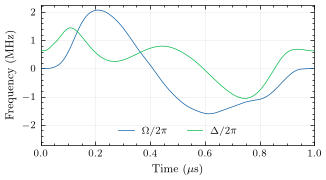

In [6]:
# A shorter version of the same panel, for a layout that cannot afford 3 inches of height.
SHORT_HEIGHT = 2.0  # inches, against 3 above
fig, ax_pulse = plt.subplots(figsize=(ONE_COLUMN, SHORT_HEIGHT))

ax_pulse.plot(time_us, omega_mhz, color=SCIENCEPLOT_COLOURS[0], lw=0.5, zorder=3,
              label=r"$\Omega/2\pi$")
ax_pulse.plot(time_us, delta_mhz, color=SCIENCEPLOT_COLOURS[1], lw=0.5, zorder=3,
              label=r"$\Delta/2\pi$")
ax_pulse.set_xlim(0, T_US)
# Less room below for the legend than the tall version, as the legend is one row
# and the panel is short.
ax_pulse.set_ylim(low - 0.3 * (high - low), high + 0.05 * (high - low))
ax_pulse.set_xlabel(r"Time ($\mu$s)")
ax_pulse.set_ylabel(r"Frequency (MHz)")
ax_pulse.grid(alpha=0.25, lw=0.4)
ax_pulse.legend(ncol=2, loc="lower center", frameon=False, handlelength=1.6)

fig.subplots_adjust(left=0.15, right=0.955, top=0.96, bottom=0.26)
print(save_figure(fig, f"fig5_large_L_{TARGET_L}_L{L_LARGE}_short"))
plt.show()
